In [3]:
#Step 1 : Intializing the model
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

response = llm.invoke("Give me a funfact about India")
print(response.content)

Did you know? India is home to the world’s only **floating post office**! Located on Dal Lake in Srinagar, the “Bharat Post” service operates from a boat that delivers mail, parcels, and even offers a small souvenir shop—all while gently bobbing on the water. It’s a unique blend of tradition and ingenuity that’s become a popular tourist attraction and a quirky piece of India’s postal history. 🌊📬


## Tool Binding?
"Tool binding is the process of providing an LLM with information about available tools, including their names, descriptions, and input schemas, so that the model can decide when and how to call them."


Tool Binding ≠ Tool Execution

bind_tools() LLM ko batata hai ki kaunse tools available hain aur unhe kaise call karna hai. Ye khud tool execute nahi karta.

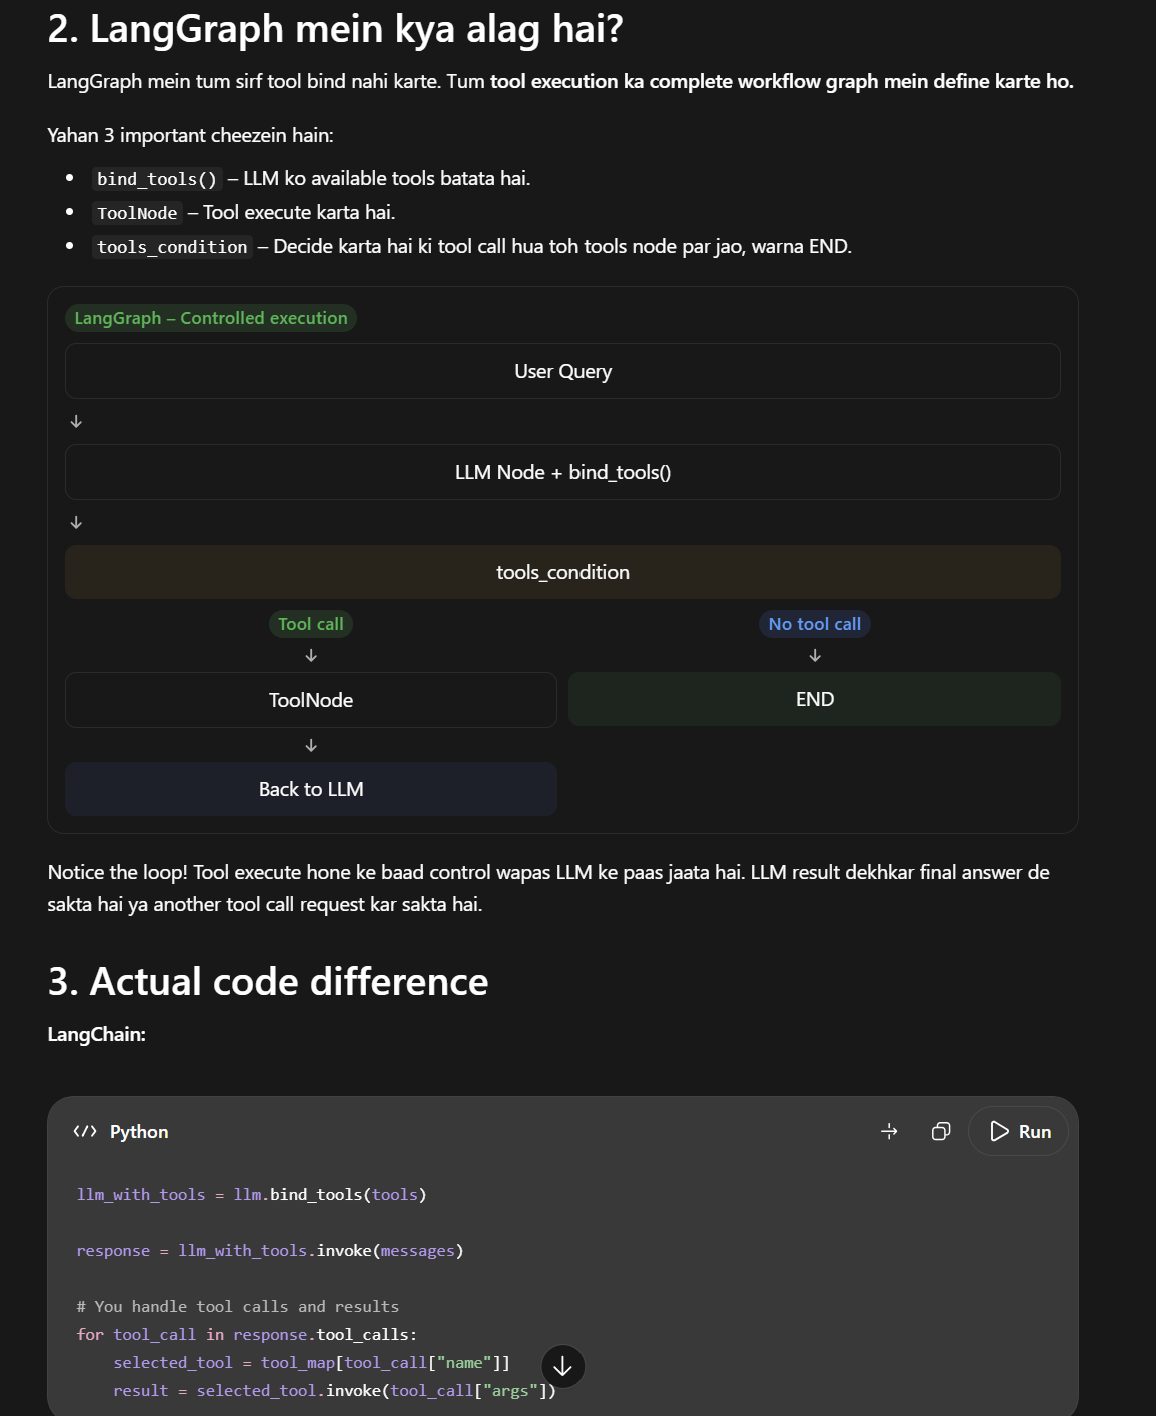
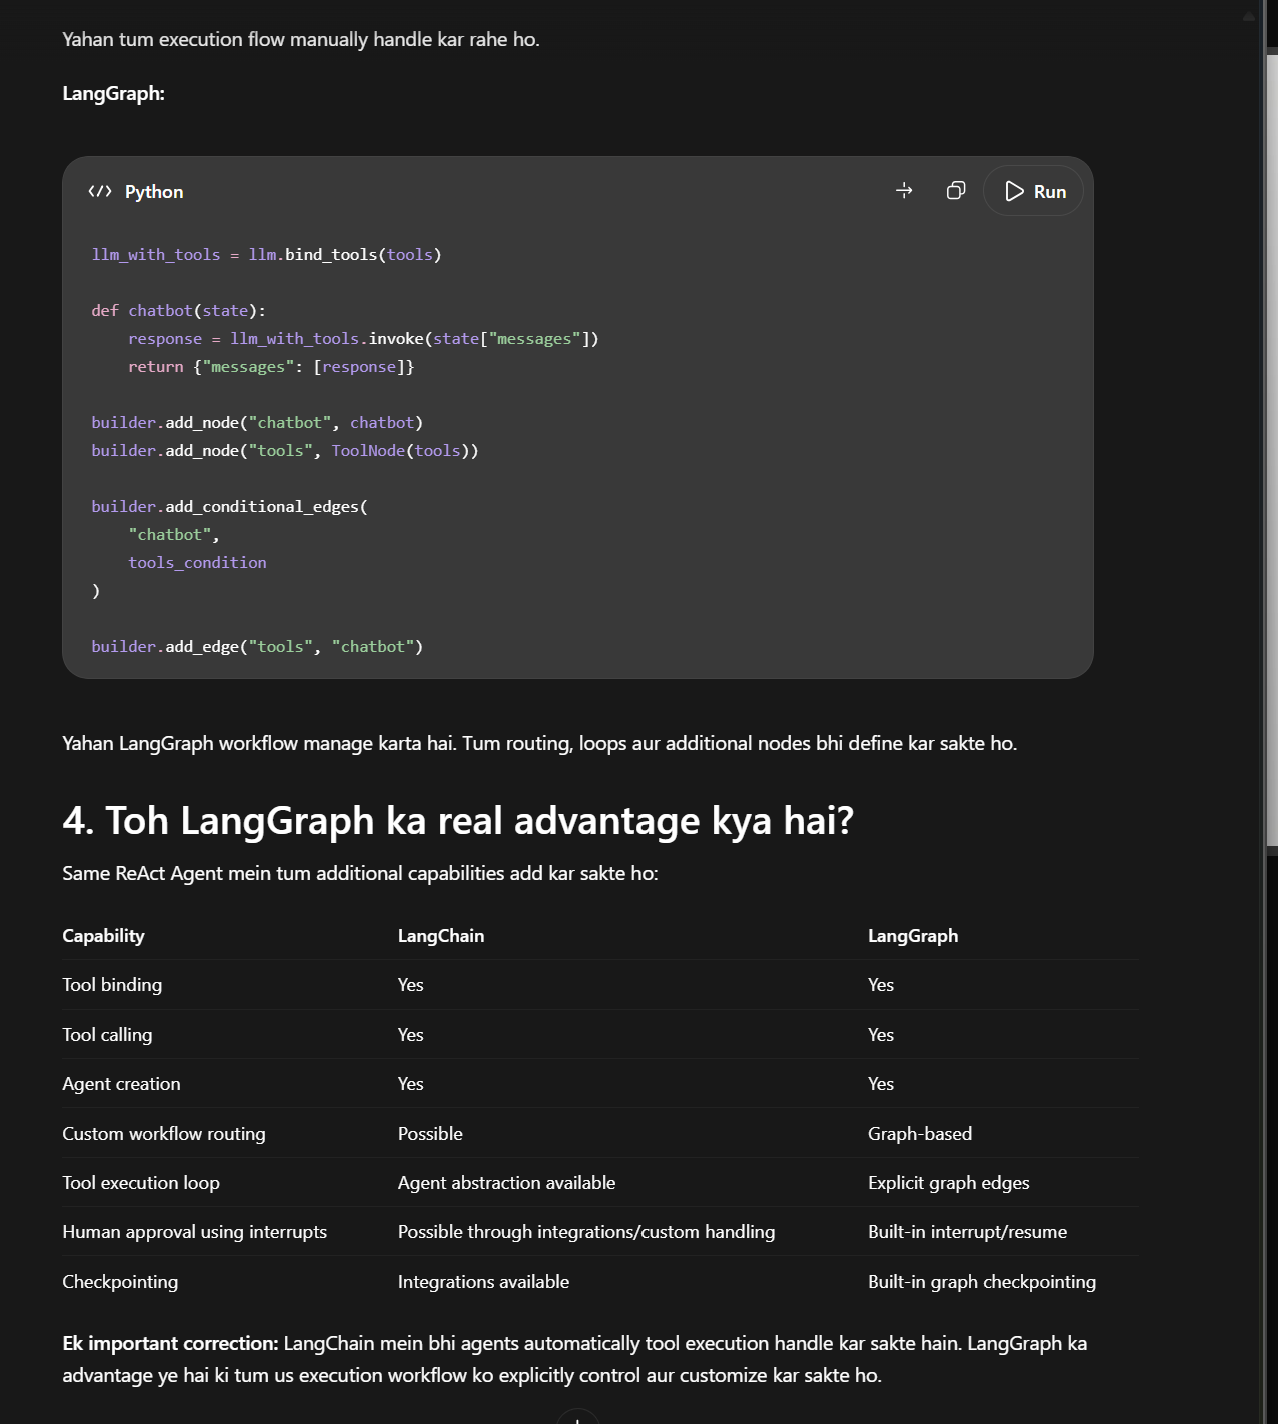

## Step 1: Define the Tool

In [4]:
from langchain_core.tools import tool
#custom tool
@tool
def multiply(a: int, b: int) -> int:
    """Multiply two numbers."""
    return a * b

## Bind the Tool to the LLM

In [ ]:
llm_with_tools = llm.bind_tools([multiply])

#Ab LLM ko pata hai:
# - Tool name: multiply
# - Description: Multiply two numbers.
# - Arguments: a and b
# - Expected types: integers.
# Important: llm original model hai. llm_with_tools tool schemas ke saath configured model runnable hai.

## Invoke the Tool from the LLM

In [ ]:
response = llm_with_tools.invoke(
    "What is 10 multiplied by 20?"
)

print(response)

#LLM tool call request return kar sakta hai.

content='' additional_kwargs={'reasoning_content': 'The user asks: "What is 10 multiplied by 20?" Simple multiplication: 200. No need to call function, but could. Use function multiply. Let\'s call it.', 'tool_calls': [{'id': 'fc_bdac3118-632c-4283-bd58-5159ee27505d', 'function': {'arguments': '{"a":10,"b":20}', 'name': 'multiply'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 71, 'prompt_tokens': 129, 'total_tokens': 200, 'completion_time': 0.149000443, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time': 0.011534688, 'prompt_tokens_details': None, 'queue_time': 0.371964738, 'total_time': 0.160535131}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_ca5edfaab2', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a1ee10-c259-72fa-880d-748f79da4aea-0' tool_calls=[{'name': 'multiply', 'args': {'a': 10, 'b': 20}, 'id': 'fc_bdac3118-632c-4283-bd58-5159ee27505d

In [7]:
print(response.tool_calls)

[{'name': 'multiply', 'args': {'a': 10, 'b': 20}, 'id': 'fc_bdac3118-632c-4283-bd58-5159ee27505d', 'type': 'tool_call'}]


Kya multiplication execute ho gaya?

Nahi!

LLM ne sirf request ki hai ki multiply tool execute karo.

Actual execution ke liye application ko tool call handle karna padega.

In [8]:
from langchain_core.messages import ToolMessage

tool_result = multiply.invoke({
    "a": 10,
    "b": 20
})

print(tool_result)

200


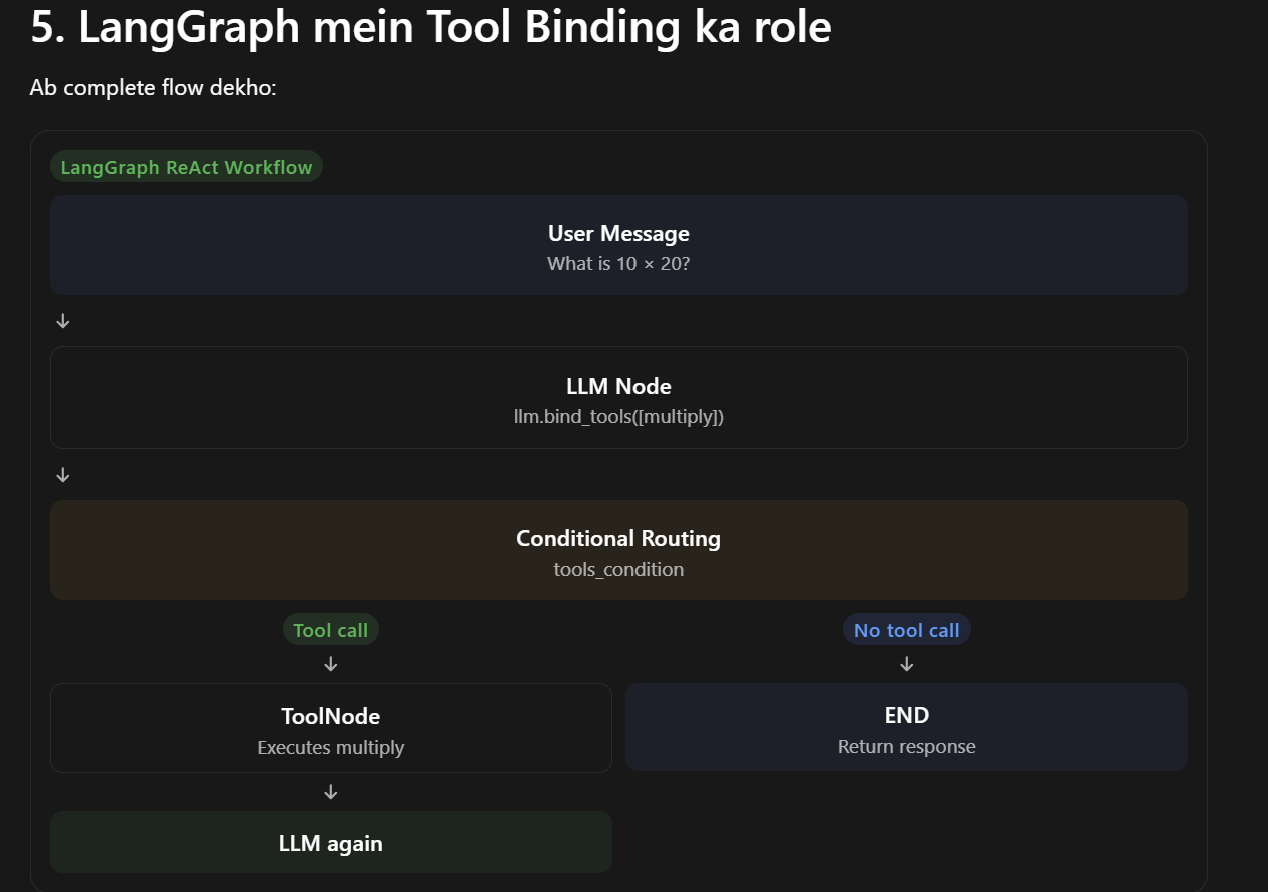

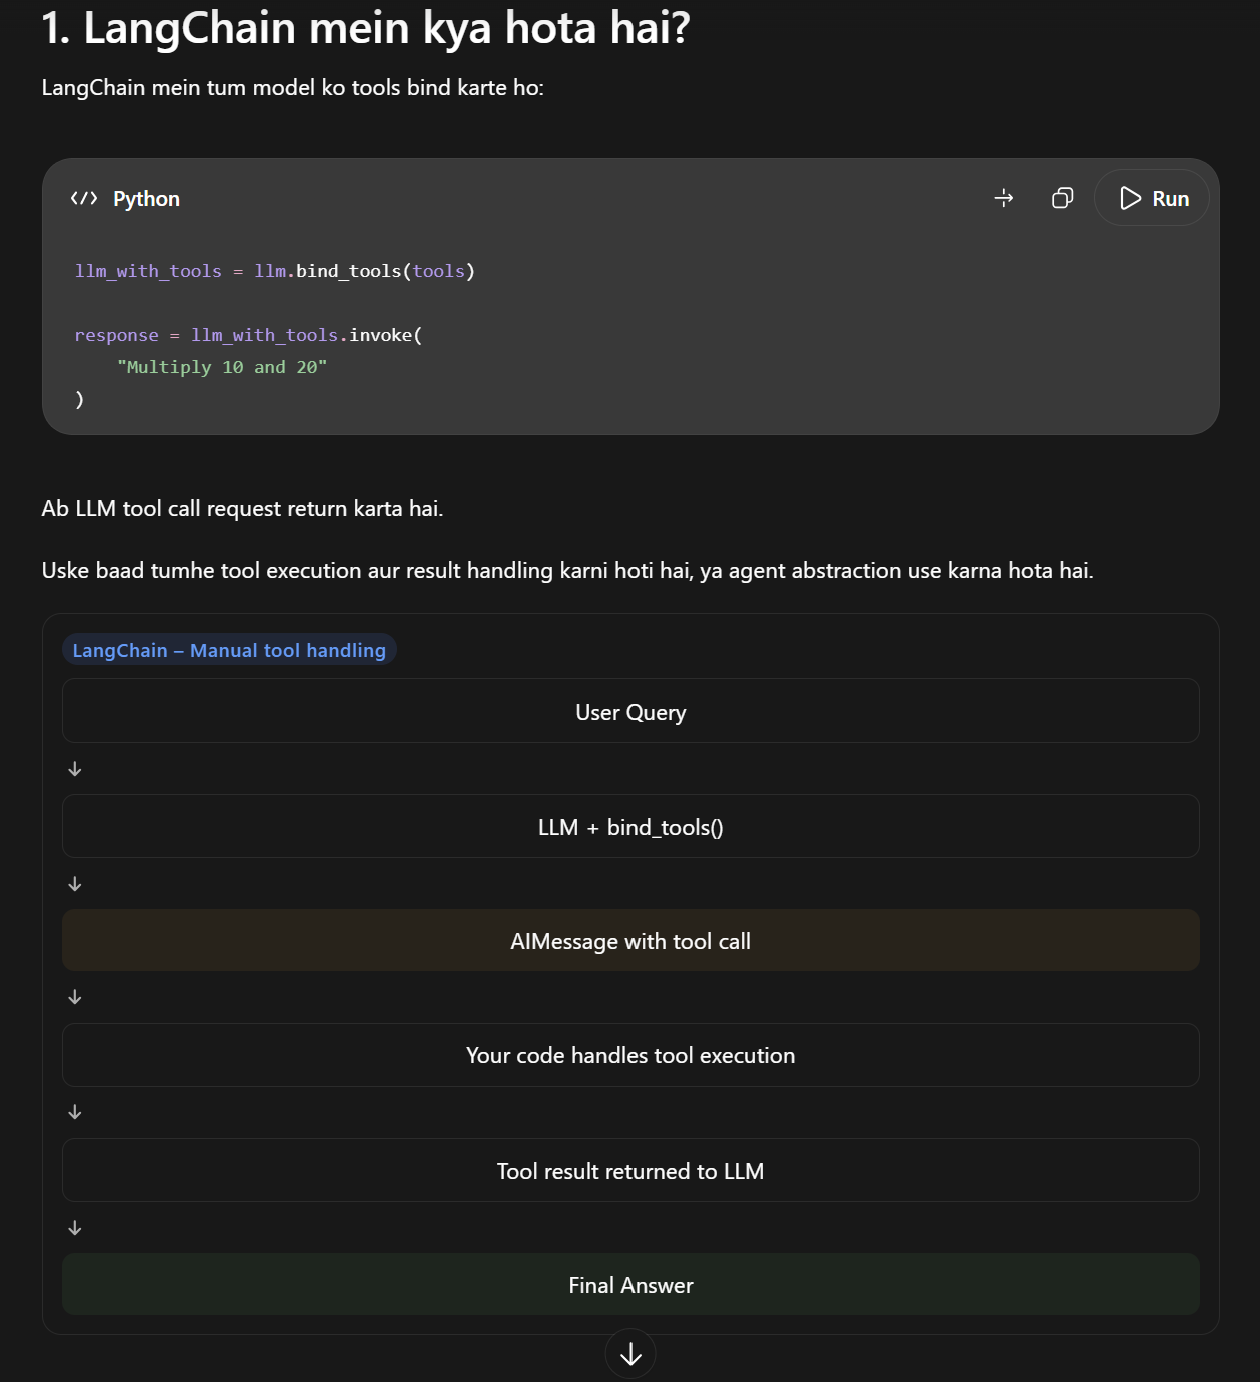